In [1]:
import zipfile
import os

zip_path = '/content/data.zip'
extract_path = '/content/data'

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Архив успешно распакован!")

Архив успешно распакован!


In [2]:
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

DATA_DIR = '/content/data'

class_names = sorted([
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d))
])

print(f"Найдено классов ({len(class_names)}): {class_names}")

class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for idx, name in enumerate(class_names)}

MAX_IMAGES_PER_CLASS = 600
IMAGE_SIZE = 32

def preprocess_symbol(img_gray, size=32):
    resized = cv2.resize(img_gray, (size, size), interpolation=cv2.INTER_AREA)
    inverted = cv2.bitwise_not(resized) / 255.0
    return inverted

X_vectors = []
y_labels = []
images_by_class = {name: [] for name in class_names}

for class_name in class_names:
    folder_path = os.path.join(DATA_DIR, class_name)
    files = os.listdir(folder_path)
    random.shuffle(files)

    count = 0
    for file_name in files:
        if count >= MAX_IMAGES_PER_CLASS:
            break
        file_path = os.path.join(folder_path, file_name)
        img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue

        images_by_class[class_name].append(img)

        processed = preprocess_symbol(img, IMAGE_SIZE)
        X_vectors.append(processed.flatten())
        y_labels.append(class_to_idx[class_name])
        count += 1

X_vectors = np.array(X_vectors, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int32)

print(f"Всего загружено образцов: {X_vectors.shape[0]}, размерность вектора: {X_vectors.shape[1]}")

Найдено классов (21): ['(', ')', '+', ',', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'X', 'h', 't', 'times', 'w', 'y']
Всего загружено образцов: 12556, размерность вектора: 1024


In [3]:
def generate_sequence_dataset(num_samples=10, min_words=2, max_words=4, min_word_len=2, max_word_len=5):
    dataset = []

    for _ in range(num_samples):
        num_words = random.randint(min_words, max_words)
        words_text = []
        sequence_images = []

        for w_idx in range(num_words):
            word_len = random.randint(min_word_len, max_word_len)
            word_chars = random.choices(class_names, k=word_len)

            display_chars = ['*' if c == 'times' else c for c in word_chars]
            words_text.append("".join(display_chars))

            for ch in word_chars:
                random_img = random.choice(images_by_class[ch])
                sequence_images.append((ch, random_img))

            if w_idx < num_words - 1:
                sequence_images.append((' ', None))

        full_text = " ".join(words_text)
        dataset.append({
            'text': full_text,
            'images': sequence_images
        })

    return dataset

generated_dataset = generate_sequence_dataset(num_samples=5)

for i, item in enumerate(generated_dataset):
    non_space_imgs = [img for ch, img in item['images'] if ch != ' ']
    print(f"Строка {i+1}: '{item['text']}' | Всего элементов: {len(item['images'])}, картинок символов: {len(non_space_imgs)}")

Строка 1: '(w8( -4+36' | Всего элементов: 10, картинок символов: 9
Строка 2: 't7 -+)99 tw6- -5' | Всего элементов: 16, картинок символов: 13
Строка 3: '3h w8 )t4 165' | Всего элементов: 13, картинок символов: 10
Строка 4: '514+6 Xw91w' | Всего элементов: 11, картинок символов: 10
Строка 5: '*60)y 3ht 5,4 664' | Всего элементов: 17, картинок символов: 14


Подбор оптимального k для k-NN:
k =  1 -> accuracy = 0.6815
k =  3 -> accuracy = 0.5510
k =  5 -> accuracy = 0.5000
k =  7 -> accuracy = 0.4773
k =  9 -> accuracy = 0.4578
k = 11 -> accuracy = 0.4435

Оптимальный классификатор: k = 1 с точностью accuracy = 0.6815


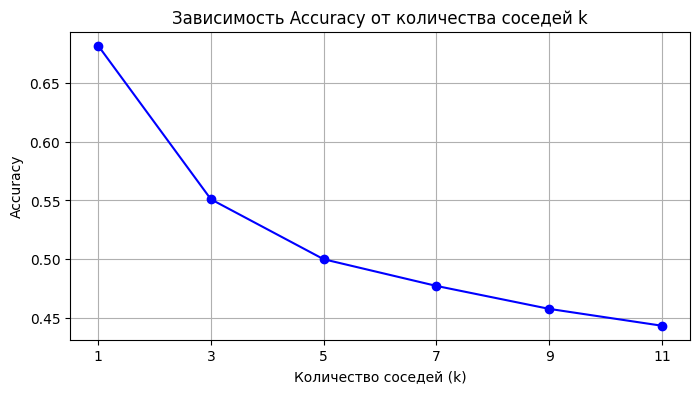

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_vectors, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

k_values = [1, 3, 5, 7, 9, 11]
accuracies = []

best_k = None
best_acc = 0.0
best_knn = None

print("Подбор оптимального k для k-NN:")
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)
    print(f"k = {k:2d} -> accuracy = {acc:.4f}")

    if acc > best_acc:
        best_acc = acc
        best_k = k
        best_knn = knn

print(f"\nОптимальный классификатор: k = {best_k} с точностью accuracy = {best_acc:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.title('Зависимость Accuracy от количества соседей k')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

=== Пример #1 ===
Сгенерированная строка : 2X *,9t
Распознанный текст     : 2X X , 9 1


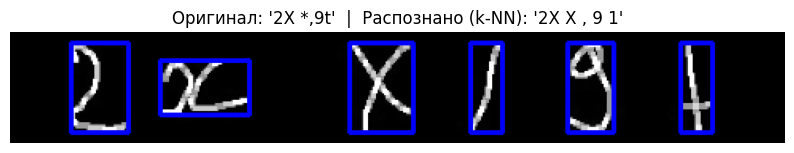

=== Пример #2 ===
Сгенерированная строка : yh7t) th,y6 )+*+ 8yt
Распознанный текст     : yh2t ) ( 4 t y, )+X7 9 y t


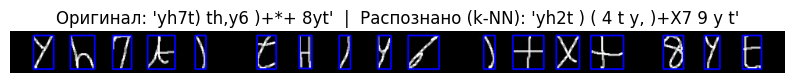

=== Пример #3 ===
Сгенерированная строка : 9-8w y9 45-4X w*
Распознанный текст     : 94y, 1 9 7yX4 X h*


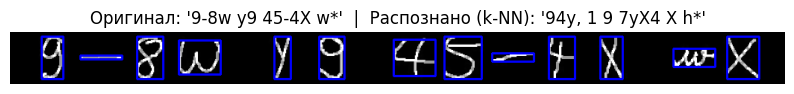

=== Пример #4 ===
Сгенерированная строка : ,5w h0 7+
Распознанный текст     : ,y9* h0 y+


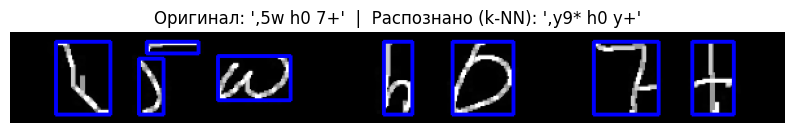

In [5]:
def render_sequence_to_image(sequence_images, target_height=64, char_spacing=12, space_width=45):
    rendered_parts = []
    rendered_parts.append(np.ones((target_height, 20), dtype=np.uint8) * 255)

    for ch, img in sequence_images:
        if ch == ' ' or img is None:
            space_block = np.ones((target_height, space_width), dtype=np.uint8) * 255
            rendered_parts.append(space_block)
        else:
            h, w = img.shape
            scale = (target_height - 10) / float(h)
            new_w = max(1, int(w * scale))
            new_h = max(1, int(h * scale))
            resized_char = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)

            char_canvas = np.ones((target_height, new_w + char_spacing), dtype=np.uint8) * 255
            y_offset = (target_height - new_h) // 2
            x_offset = char_spacing // 2
            char_canvas[y_offset:y_offset+new_h, x_offset:x_offset+new_w] = resized_char

            rendered_parts.append(char_canvas)

    rendered_parts.append(np.ones((target_height, 20), dtype=np.uint8) * 255)

    full_image = np.hstack(rendered_parts)
    return full_image


def recognize_sequence_with_knn(full_img_gray, knn_model, space_threshold=32):
    kernel = np.ones((3, 3), np.uint8)
    img_gray = cv2.erode(full_img_gray, kernel, iterations=1)
    img_gray = cv2.bitwise_not(img_gray)

    base_size = (img_gray.shape[0] + 6, img_gray.shape[1] + 6)
    base = np.zeros(base_size, dtype=np.uint8)
    base[3:img_gray.shape[0]+3, 3:img_gray.shape[1]+3] = img_gray

    img_rgb = cv2.cvtColor(base, cv2.COLOR_GRAY2RGB)

    ret, thresh = cv2.threshold(img_rgb, 127, 255, 0)
    thresh = np.uint8(thresh)
    contours, _ = cv2.findContours(thresh[:, :, 0], cv2.RETR_EXTERNAL, 2)

    crops = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if w * h > 50:
            cv2.rectangle(img_rgb, (x, y), (x + w, y + h), (0, 0, 255), 2)
            crops.append([x, y, w, h])

    crops.sort(key=lambda item: item[0])

    recognized_chars = []
    prev_right_x = None

    for x, y, w, h in crops:
        if prev_right_x is not None:
            gap = x - prev_right_x
            if gap > space_threshold:
                recognized_chars.append(' ')
        prev_right_x = x + w

        x_pad = max(0, x - 3)
        y_pad = max(0, y - 3)
        w_pad = w + 5
        h_pad = h + 3
        crop_img = img_gray[y_pad:y_pad+h_pad, x_pad:x_pad+w_pad]

        pad_size = (crop_img.shape[0] + 2, crop_img.shape[1] + 30)
        padded_symbol = np.zeros(pad_size, dtype=np.uint8)
        padded_symbol[1:crop_img.shape[0]+1, 15:crop_img.shape[1]+15] = crop_img

        resized = cv2.resize(padded_symbol, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA)
        vector = (resized.astype(np.float32) / 255.0).flatten().reshape(1, -1)

        pred_idx = knn_model.predict(vector)[0]
        pred_char = idx_to_class[pred_idx]
        if pred_char == 'times':
            pred_char = '*'

        recognized_chars.append(pred_char)

    recognized_text = "".join(recognized_chars)
    return recognized_text, img_rgb


test_sequences = generate_sequence_dataset(num_samples=4)

for idx, sample in enumerate(test_sequences, 1):
    seq_image = render_sequence_to_image(sample['images'])
    predicted_text, boxed_img = recognize_sequence_with_knn(seq_image, best_knn)

    print(f"=== Пример #{idx} ===")
    print(f"Сгенерированная строка : {sample['text']}")
    print(f"Распознанный текст     : {predicted_text}")

    plt.figure(figsize=(10, 2))
    plt.imshow(boxed_img)
    plt.title(f"Оригинал: '{sample['text']}'  |  Распознано (k-NN): '{predicted_text}'")
    plt.axis('off')
    plt.show()